In [ ]:
# [FIRST CELL] AXIA D11 / venv bootstrap + optional CUDA backend.
# 실제 Notebook 첫 번째 코드 셀입니다. 첫 실행 때 venv/패키지를 설치하고 Jupyter 커널을 등록합니다.
# 다음 실행부터는 등록된 커널 'AXIA D11 (venv)'로 전환해야만 [PASS SETUP]이 출력됩니다.
# CPU는 여유 디스크가 적은 WSL2 PC에 권장. NVIDIA GPU를 쓰려면 아래 TORCH_VARIANT 수정.
import os
import sys
import subprocess
from pathlib import Path
from importlib import metadata as _md

# 학생이 선택하는 두 설정. 'cuda' 강제 요청 시 실패를 숨기지 않습니다.
TORCH_VARIANT = os.environ.get("AXIA_D11_TORCH_VARIANT", "cpu").strip().lower()
# cpu | cu126 | cu128 | cu130  (PyTorch 2.10.0 공식 wheel 저장소)
DEVICE_MODE = os.environ.get("AXIA_D11_DEVICE_MODE", "auto").strip().lower()
# auto | cpu | cuda  (auto는 설치된 CUDA가 실제 작동할 때만 GPU 사용)

if TORCH_VARIANT not in {"cpu", "cu126", "cu128", "cu130"}:
    raise ValueError("SETUP_HOLD: TORCH_VARIANT는 cpu/cu126/cu128/cu130 중 하나입니다.")
if DEVICE_MODE not in {"auto", "cpu", "cuda"}:
    raise ValueError("SETUP_HOLD: DEVICE_MODE는 auto/cpu/cuda 중 하나입니다.")
if DEVICE_MODE == "cuda" and TORCH_VARIANT == "cpu":
    raise ValueError("SETUP_HOLD: DEVICE_MODE=cuda에는 TORCH_VARIANT=cu128 등 CUDA wheel이 필요합니다.")

LESSON_DIR = Path.cwd().resolve()
assert (LESSON_DIR / "requirements.txt").is_file(), "SETUP_HOLD: 먼저 lesson11 폴더에서 Notebook을 여세요."
AXIA_VENV = Path(os.environ.get("AXIA_D11_VENV_DIR", str(LESSON_DIR / f".venv-axia-d11-{TORCH_VARIANT}"))).expanduser().resolve()
KERNEL_NAME = f"axia-d11-{TORCH_VARIANT}"
KERNEL_DISPLAY = f"AXIA D11 (venv · {TORCH_VARIANT.upper()})"
REQUIRED_VERSIONS = {"numpy":"2.3.5", "pandas":"2.2.3", "matplotlib":"3.10.8",
                     "scikit-learn":"1.8.0", "torch":"2.10.0", "ipykernel":"7.2.0"}

def _versions_in_python(python):
    """실제 해당 venv의 Python subprocess에서 설치 상태를 점검합니다."""
    check = (
        "import json,importlib.metadata as m; "
        f"print(json.dumps({{k:m.version(k) for k in {list(REQUIRED_VERSIONS)!r}}}))"
    )
    run = subprocess.run([str(python), "-c", check], text=True, capture_output=True)
    if run.returncode != 0:
        return None
    import json
    return json.loads(run.stdout.strip())

def _is_ready(versions):
    return bool(versions) and all(versions.get(k, "").split("+")[0] == v
                                   for k, v in REQUIRED_VERSIONS.items())

inside_venv = Path(sys.prefix).resolve() == AXIA_VENV
venv_python = AXIA_VENV / "bin/python"

# venv별 설치: Jupyter를 이 venv 안에서 시작해도 첫 셀이 나머지 패키지를 설치합니다.
def _install_missing():
    found = _versions_in_python(venv_python)
    # CPU/CUDA wheel 차이를 구분합니다. torch==2.10.0의 local version에는 +cpu/+cu128 등이 붙습니다.
    backend_matches = bool(found) and (
        (TORCH_VARIANT == "cpu" and "+cpu" in found.get("torch", "")) or
        (TORCH_VARIANT != "cpu" and "+cu" in found.get("torch", ""))
    )
    if _is_ready(found) and backend_matches:
        return False
    pip = [str(venv_python), "-m", "pip"]
    wheel_url = f"https://download.pytorch.org/whl/{TORCH_VARIANT}"
    if not backend_matches:
        print("[SETUP] PyTorch 2.10.0 wheel 설치:", TORCH_VARIANT, flush=True)
        subprocess.run(pip + ["install", "torch==2.10.0", "--index-url", wheel_url,
                              "--force-reinstall"], check=True)
    print("[SETUP] 나머지 pinned 패키지 설치: requirements.txt", flush=True)
    subprocess.run(pip + ["install", "-r", str(LESSON_DIR / "requirements.txt")], check=True)
    final = _versions_in_python(venv_python)
    if not _is_ready(final):
        raise RuntimeError("SETUP_HOLD: pip 완료 후에도 pinned 패키지 누락. 최초 오류와 버전을 확인하세요.")
    return True

if not inside_venv:
    if not venv_python.is_file():
        print("[SETUP] 가상환경 생성:", AXIA_VENV, flush=True)
        subprocess.run([sys.executable, "-m", "venv", str(AXIA_VENV)], check=True)
    _install_missing()
    subprocess.run([str(venv_python), "-m", "ipykernel", "install", "--user",
                    "--name", KERNEL_NAME, "--display-name", KERNEL_DISPLAY], check=True)
    print("[SETUP_HOLD] venv 등록 완료. 현재 커널은 아직", sys.executable)
    print(f"[SETUP_HOLD] Kernel → Change Kernel → {KERNEL_DISPLAY!r} 선택 후 Restart & Run All")
    raise RuntimeError("SETUP_SWITCH_KERNEL_REQUIRED: venv 커널 전환 후 다시 실행하세요. 아직 PASS가 아닙니다.")

if _install_missing():
    # 같은 venv에서 Jupyter를 시작한 학생: 패키지 설치는 성공하였으나 재시작해야 새 모듈을 안전하게 로드합니다.
    print("[SETUP_HOLD] 현재 venv에 패키지 설치 완료. Kernel → Restart Kernel & Run All")
    raise RuntimeError("SETUP_RESTART_KERNEL_REQUIRED: 재시작 후 [PASS SETUP] 확인하세요.")
versions = {k:_md.version(k) for k in REQUIRED_VERSIONS}
if not _is_ready(versions):
    raise RuntimeError("SETUP_HOLD: 가상환경 의존성 버전 불일치. 설치 커널에서 pip 목록을 확인하세요.")
import torch as _torch_setup
if TORCH_VARIANT == "cpu" and _torch_setup.version.cuda is not None:
    raise RuntimeError("SETUP_HOLD: CPU 선택인데 CUDA torch가 설치됨. 새 venv에서 CPU wheel로 재설치하세요.")
if TORCH_VARIANT != "cpu" and _torch_setup.version.cuda is None:
    raise RuntimeError("SETUP_HOLD: CUDA 선택인데 CPU torch가 설치됨. 새 venv에서 CUDA wheel로 재설치하세요.")
if DEVICE_MODE == "cuda" and not _torch_setup.cuda.is_available():
    raise RuntimeError("SETUP_HOLD: CUDA 강제 선택이지만 현재 커널에서 GPU를 사용할 수 없습니다. CPU를 선택하거나 Windows NVIDIA/WSL2 드라이버를 점검하세요.")
print("[PASS SETUP] venv 경로=", sys.prefix)
print("[PASS SETUP] torch=", _torch_setup.__version__, "wheel=", TORCH_VARIANT,
      "requested_device=", DEVICE_MODE, "cuda_available=", _torch_setup.cuda.is_available())
print("[PASS SETUP] Python=", sys.version.split()[0], "kernel=", KERNEL_NAME)
# 다음 셀 S1에서 실사용 장치와 GPU 연산 성공을 추가 검증합니다.


# AXIA D11 — WSL2 venv 학생 실습 TODO 워크북

**주의:** S1~S3은 실행 가능한 공통 기초 실습이고 S4~S6은 학생이 완성해야 할 EXPECTED_RED TODO입니다. 강사용 AE 정답·checkpoint·완료된 모델 점수는 포함하지 않습니다.

학습목표: AutoEncoder 기반 정상상태 재구성 원리 이해 / 재구성 오차 기반 이상상태 판정 실습. 합성 데이터만 사용하며 로봇 제어 없음.


## 시작하기 전에 — 첫 번째 셀에서 venv 생성과 GPU 옵션 선택

**첫 번째 코드 셀(SETUP)은 실행 환경 구성용입니다.** 최초 실행 시 `.venv-axia-d11-cpu` (GPU 선택 시 `.venv-axia-d11-cu128` 등) 폴더에 가상환경을 만들고, PyTorch 2.10.0 및 `requirements.txt` 패키지를 설치하고, `AXIA D11 (venv · CPU)` 등 Jupyter 커널을 등록합니다. **venv 설치와 커널 전환은 서로 다른 단계**이며 이미 돌아가는 커널은 `source .../activate`로 교체할 수 없습니다.

1. **기본: CPU** — 첫 셀 `TORCH_VARIANT="cpu"`, `DEVICE_MODE="auto"`로 시작합니다. 인터넷과 저장 용량을 아끼려는 학생에게 권장합니다.
2. **NVIDIA GPU 선택:** WSL2에서 Windows NVIDIA 드라이버와 GPU 접근이 준비된 경우 `TORCH_VARIANT="cu128"`(또는 환경에 맞는 `cu126`/`cu130`), `DEVICE_MODE="cuda"`로 바꾼 뒤 처음부터 실행합니다. GPU wheel은 대용량이므로 여유 디스크 공간을 확인합니다. CUDA 지원이 없다면 오류로 중지되며 GPU PASS를 내지 않습니다.
3. **첫 실행:** `[SETUP_HOLD]`가 나타나면 `Kernel → Change Kernel → AXIA D11 (venv · CPU)` 또는 해당 CUDA 커널을 선택하고 **Restart & Run All**을 실행합니다. 가상환경에서 `[PASS SETUP]`과 S1~S6의 결과가 나와야 정상입니다.
4. **자동 선택(`auto`)의 의미:** 설치된 PyTorch 빌드와 GPU가 모두 CUDA를 지원할 때만 GPU를 사용합니다. CPU wheel을 설치한 상태에서 `auto`를 선택하면 CPU입니다. **CUDA 강제 모드(`cuda`)는 CPU로 조용히 대체하지 않습니다.**

**설치 오류 처리:** `ensurepip` 실패는 Ubuntu `python3-venv` 미설치 가능성, 패키지 다운로드 실패는 인터넷/디스크 부족, `torch.cuda.is_available()=False`는 NVIDIA 드라이버·WSL2/CUDA wheel 경계를 확인합니다. WSL2에 Linux용 NVIDIA 그래픽 드라이버를 별도로 설치하는 방식은 권장하지 않습니다.

**일치해야 할 경로:** 설치용 `pip`는 항상 해당 `.venv-axia-d11-<backend>/bin/python -m pip`로 호출되며, 다음 코드는 실제 실행 커널의 `sys.prefix`가 그 가상환경인지 검증합니다. Notebook 자체가 시스템 Python에 패키지를 설치하지 않습니다.


## 핵심 용어 — 처음 나올 때 뜻부터 확인하세요

| 용어(English) | 간단한 뜻 | 이번 Notebook에서의 예 |
|---|---|---|
| **샘플(Sample)** | 한 시각의 센서 수치 한 행 | 전류·토크·가속도 0.1초 간격 합성값 |
| **트레이스(Trace)** | 사건 하나에 속한 샘플의 연속 기록 | `TST_A_00`의 100개 샘플 |
| **윈도우(Window)** | Trace 안의 연속된 짧은 구간 | Sample 40~49 → W4 |
| **특징(Feature)** | Window를 대표하는 통계값 | 센서 3개 × 평균/표준편차 = 6특징 |
| **학습/검증/시험(Train/Valid/Test)** | 기준을 학습/경고선을 선택/마지막 평가 | 각각 정상 240/정상 80/유효 100 Window |
| **스케일러(StandardScaler)** | Train 평균·표준편차로 수치를 정규화 | `fit_transform(X_train)`, `transform(X_valid)` |
| **오토인코더(AutoEncoder, AE)** | 입력과 비슷한 값을 스스로 복원하도록 학습하는 모델 | `(B,6) → (B,3) → (B,6)` |
| **인코더(Encoder)/디코더(Decoder)** | 압축/복원 단계 | `6→8→3` / `3→8→6` |
| **잠재 표현(Latent vector)** | 압축된 중간 표현 | `(B,3)`; 고장 클래스 수가 아님 |
| **재구성 오차(MSE)** | 같은 위치의 입력·복원 차이를 제곱해 평균한 값 | 6개 차이가 ±0.1 → `0.01` |
| **임계값(Threshold/Cutoff)** | 경고 여부를 나누는 점수선 | 정상 Valid MSE의 95% 분위수 |
| **오탐(False Positive, FP)** | 실제 정상인데 WARNING | 정상 82개 중 잘못 경고한 수 |
| **미탐(False Negative, FN)** | 실제 이상인데 NORMAL | 합성 이상 18개 중 놓친 수 |
| **INSUFFICIENT_DATA** | 품질 오류로 모델 점수 산출을 보류 | 결측·샘플 누락·시각 역행·시간 간격 오류 |

### 실습 준비

- **권장 실행:** Windows 10/11의 **WSL2 Ubuntu 24.04**, **Python 3.12**, JupyterLab 또는 VS Code Jupyter 커널. **CPU 기본·CUDA 선택 가능**하도록 작성했습니다.
- **이 제작 환경의 실측:** Linux Python 3.13.5, PyTorch 2.10.0+cpu, NumPy 2.3.5, Pandas 2.2.3, scikit-learn 1.8.0, Matplotlib 3.10.8. **사용자 WSL2/Jazzy/Harmonic 환경에서의 실행은 아직 확인하지 않았습니다.**
- **데이터·인터넷:** 학습 중 원격 데이터를 내려받지 않습니다. 첫 패키지 설치에만 인터넷이 필요할 수 있습니다. 합성 원본은 환경 준비 코드 다음의 **STEP 1 코드 셀에서 생성**하며, 별도 CSV나 앞 교시의 변수는 필요하지 않습니다.
- **실행 순서:** 1~6단계의 코드 셀을 반드시 위에서 아래로 실행하세요. `assert`에서 멈춘 경우 원인을 수정하기 전에는 다음 단계의 `[PASS]`를 주장하지 않습니다.
- **설치 상세 명령:** 동봉된 `student_guide.md`와 `requirements.txt`를 참고하세요. PyTorch CPU 휠을 먼저 설치해 대용량 CUDA 의존성을 피하는 방법을 안내합니다.

<div style="background:#fff2d4;border-left:5px solid #d5a24d;border-radius:8px;padding:14px 18px;margin:14px 0"><b>주의 · 합성 데이터·물리 안전의 경계</b><div style="margin-top:6px">이번 데이터는 **LESSON11_INDEPENDENT_SYNTHETIC**이라는 독립 교육용 생성 자료입니다. 과거 AXIA C01 원본과 행 수·형식은 유사하지만 **동일한 CSV나 동일한 IF/AE 모델/점수는 아닙니다**. ROS 2·Gazebo·실제 TurtleBot3·Nav2·cmd_vel·SW Stop·인증된 E-Stop을 실행하지 않습니다.</div></div>


## 1단계 (15분) · 문제 접수: 전류가 증가하면 바로 고장일까요?

**왜 필요한가?** 실제 현장에서 한 그래프가 달라졌다고 모터 고장을 확정하면 정상 부하 변화와 센서 고장을 구별할 수 없습니다. 오늘의 역할은 **증거의 경로를 재구성하는 분석가**입니다.

**비유:** 환자의 체온이 올랐다는 기록만으로 원인을 단정하지 않는 것과 같습니다. 재측정 상태·환경·다른 징후가 필요합니다. 비유의 한계: AE의 복원오차는 질병 진단 같은 인과 추론이 아니라 *정상 패턴과 다른 정도*에 대한 점수입니다.

**먼저 예측:** 어떤 상황에서 전류가 올라갈 수 있을까요? ① 정상 부하 증가 ② 센서 결측 ③ 실제 구동 이상. 셋 중 하나라고 결론 낼 수 있습니까?


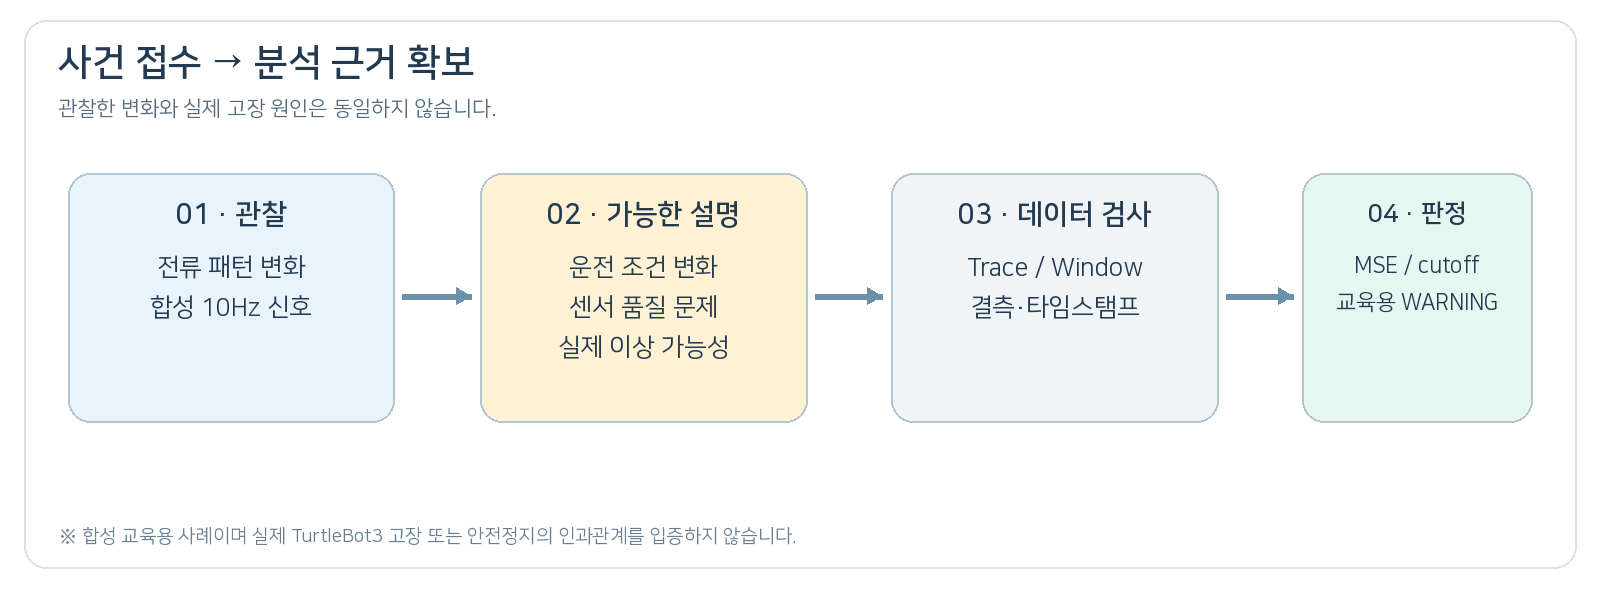

**그림 읽기:** 왼쪽 관찰 사실이 직접 고장 확정으로 이어지지 않으며, 품질 검사 뒤에만 교육용 경고 판단이 있습니다.


### 코드 설명 · STEP 1 — “사건 원본을 만든다”

- **입력:** 고정 시드 `SEED=2409`, 합성 10 Hz(`DT_NS=100_000_000`), 46개 Trace 목록. 외부 네트워크나 실물 센서를 쓰지 않습니다.
- **출력:** `raw_df`의 **4,599행**, Trace 46개, Train/Valid/Test 원본 행 수 2,400/800/1,399, 그리고 **`TST_A_00` 합성 전류 시계열 그림**.
- **설계 이유:** 데이터가 학습 전에 어떻게 생겼는지 확인한 뒤, 품질 검사를 거치지 않고 Window를 만들면 어떤 오류가 생길지 관찰하기 위해서입니다. Test 이상은 시각적으로 4.0~7.0초에 주입하지만, **모델은 그 정답을 학습에 사용하지 않습니다.**
- **확인 방법:** 전체 행 수·Trace 수·분할 행 수를 `assert`로 검사합니다. 출력 `[PASS S1]`은 **합성 생성 계약**만 통과했음을 뜻합니다. 아직 AE 학습 PASS가 아닙니다.


In [ ]:
import sys, platform
import numpy as np
import pandas as pd
import torch
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, precision_score, recall_score
from torch import nn

# 실행 범위: ROS·Gazebo·실물 로봇 없이 CPU에서만 독립 합성 실험.
SEED = 2409
RNG = np.random.default_rng(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
# 첫 셀의 DEVICE_MODE 선택을 실제 Tensor 연산에 적용합니다.
if DEVICE_MODE == "cuda" and not torch.cuda.is_available():
    raise RuntimeError("S1_DEVICE_HOLD: CUDA를 요청했지만 torch.cuda.is_available()=False")
DEVICE = torch.device("cuda:0" if DEVICE_MODE != "cpu" and torch.cuda.is_available() else "cpu")
try:
    _device_probe = torch.tensor([2.0, 3.0], device=DEVICE)
    assert torch.allclose(_device_probe.square(), torch.tensor([4.0, 9.0], device=DEVICE))
except (RuntimeError, AssertionError) as exc:
    raise RuntimeError(f"S1_DEVICE_HOLD: {DEVICE}에서 실제 Tensor 연산 실패: {exc}") from exc
print(f"[DEVICE] requested={DEVICE_MODE} actual={DEVICE.type} torch_cuda={torch.version.cuda}"
      f" gpu_name={torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'N/A'}")
matplotlib.rcParams.update({"font.family": "NanumGothic", "axes.unicode_minus": False,
                             "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22})
DT_NS = 100_000_000    # 10 Hz 합성 시간축의 0.1초; 실제 센서 주기는 아님.
N_SAMPLES = 100       # Trace 하나당 원래 100 샘플
NORMAL_TRAIN = [f"TRN_{i:02d}" for i in range(24)]
NORMAL_VALID = [f"VAL_{i:02d}" for i in range(8)]
TEST_NORMAL = [f"TST_N_{i:02d}" for i in range(4)]
TEST_ANOMALY = [f"TST_A_{i:02d}" for i in range(6)]
TEST_QUALITY = [f"TST_Q_{i:02d}" for i in range(4)]
ANOMALY_KINDS = ["CURRENT_SPIKE", "TORQUE_DRIFT", "ACCEL_VIBRATION"] * 2
QUALITY_KINDS = ["MISSING_VALUE", "SAMPLE_GAP", "STAMP_REGRESSION", "TIMESTAMP_DRIFT"]

def make_trace(tid, split, kind="NORMAL", quality=None):
    """이 강의용 독립 합성 생성기; 원본 AXIA C01 generator의 실제 로그가 아님."""
    phase = RNG.uniform(0, 2*np.pi)
    bias = RNG.normal(0, 0.024)
    rows = []
    for i in range(N_SAMPLES):
        t = i / 10.0
        current = 2.0 + bias + 0.060*np.sin(.8*t+phase) + RNG.normal(0,.038)
        torque = .40 + bias*.16 + .015*np.sin(1.0*t+phase/2) + RNG.normal(0,.012)
        accel = .02 + .042*np.sin(1.3*t+phase) + RNG.normal(0,.026)
        is_anomaly = split=="test" and kind != "NORMAL" and 40 <= i < 70
        if is_anomaly:
            if kind == "CURRENT_SPIKE": current += 1.20
            elif kind == "TORQUE_DRIFT": torque += .18 + .022*(i-40)
            elif kind == "ACCEL_VIBRATION": accel += .47 * (-1 if i%2 else 1)
        timestamp_ns = i * DT_NS
        if quality == "MISSING_VALUE" and i == 55: current = np.nan
        if quality == "SAMPLE_GAP" and i == 55: continue
        if quality == "STAMP_REGRESSION" and i == 55: timestamp_ns = 53*DT_NS
        if quality == "TIMESTAMP_DRIFT" and i >= 50:
            timestamp_ns = 50*DT_NS + (i-50)*130_000_000
        rows.append({"split": split, "trace_id": tid, "sample_idx": i,
                     "timestamp_ns": timestamp_ns, "current_a": current,
                     "torque_nm": torque, "accel_mps2": accel,
                     "truth_label": -1 if quality else int(is_anomaly),
                     "injection_kind": kind if is_anomaly else "NONE"})
    return rows

raw = []
for name in NORMAL_TRAIN: raw.extend(make_trace(name,"train"))
for name in NORMAL_VALID: raw.extend(make_trace(name,"valid"))
for name in TEST_NORMAL: raw.extend(make_trace(name,"test"))
for name,kind in zip(TEST_ANOMALY,ANOMALY_KINDS):
    raw.extend(make_trace(name,"test",kind=kind))
for name,quality in zip(TEST_QUALITY,QUALITY_KINDS):
    raw.extend(make_trace(name,"test",quality=quality))
raw_df = pd.DataFrame(raw)
assert len(raw_df)==4599
assert raw_df.trace_id.nunique()==46
assert raw_df.groupby('split').size().to_dict()=={'train':2400,'valid':800,'test':1399}
assert raw_df.loc[raw_df.split=='test','trace_id'].nunique()==14
print("Python",sys.version.split()[0],"OS",platform.system())
print("torch",torch.__version__,"numpy",np.__version__,"pandas",pd.__version__,
      "sklearn",sklearn.__version__,"matplotlib",matplotlib.__version__)
print("data provenance: LESSON11_INDEPENDENT_SYNTHETIC / seed",SEED)
print("raw rows",len(raw_df),"traces",raw_df.trace_id.nunique(),
      "split rows",raw_df.groupby('split').size().to_dict())
view=raw_df[raw_df.trace_id=="TST_A_00"]
fig, ax=plt.subplots(figsize=(11,2.8))
ax.plot(view.sample_idx/10,view.current_a,color="#147d88",lw=1.8,label="합성 전류(A)")
ax.axvspan(4,7,color="#ffd99d",alpha=.5,label="이상 주입 구간[4.0,7.0)")
ax.set(xlabel="합성 시간(초)",ylabel="current_a [A]",title="사건 접수 · 전류 급증 Trace (실제 로봇 계측 아님)")
ax.legend(loc="upper right",fontsize=9);plt.tight_layout();plt.show()
print("[PASS S1] 독립 합성 원본 4599행 / 46 Trace / Train·Valid·Test 분리")


### 출력 해설 · STEP 1

그래프의 연노랑 구간은 독립 합성 전류 증가를 **의도적으로 주입**한 4.0~7.0초입니다. 여기서 급증을 관찰할 수 있지만 그 원인이 실제 모터 고장이라는 증거는 없습니다. **4,599행**인 이유는 품질 문제 Trace 한 곳에서 Sample 55가 빠지도록 생성했기 때문입니다. 분할은 **Trace ID 단위**로 먼저 확정했습니다.

**학생 질문:** 그림의 진한 전류 상승은 “관찰”인가요 “고장 확정”인가요? 답: 관찰이며 원인은 별도로 검증해야 합니다.


## 2단계 (25분) · Trace를 Window로 바꾸고 데이터 품질을 확인하기

**문제:** 센서 기록 한 줄에서 바로 이상 상태를 판단하면 아주 짧은 잡음과 지속된 패턴을 구별하기 어렵습니다. 그리고 Sample 55가 빠진 Trace를 무조건 10개씩 잘라 버리면 **Window 경계와 시간**이 잘못됩니다.

**비유:** 긴 영화 한 편은 Trace이고, 연속된 1초 장면이 Window입니다. 같은 영화에서 떼어 낸 장면을 Train과 Test에 동시에 넣는 것은 동일한 작품을 연습과 시험에 중복 사용한 것입니다. **비유의 한계:** 여기서는 영상을 다루는 게 아니라 수치 시계열입니다.


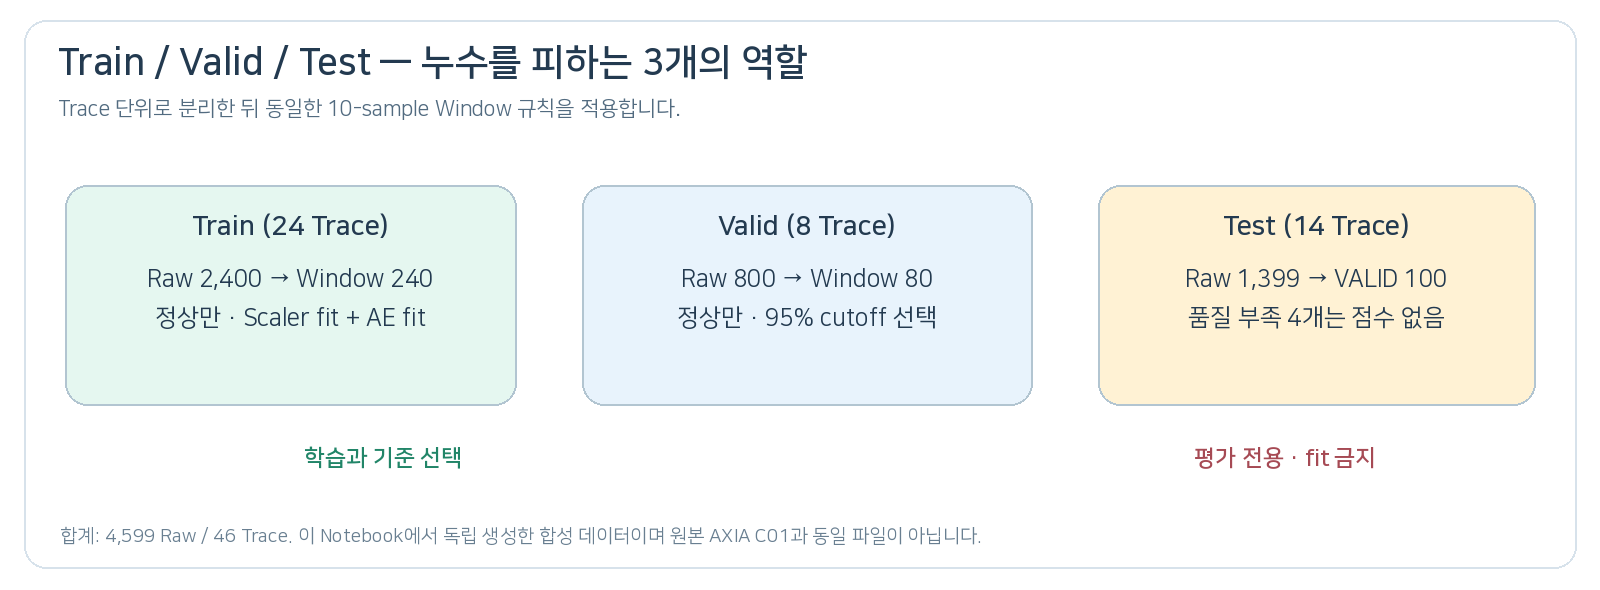

**그림 읽기:** 24/8/14 Trace 분리와 240/80/100 VALID Window를 명시합니다. Test 품질 부족 4개는 점수를 내지 않습니다.


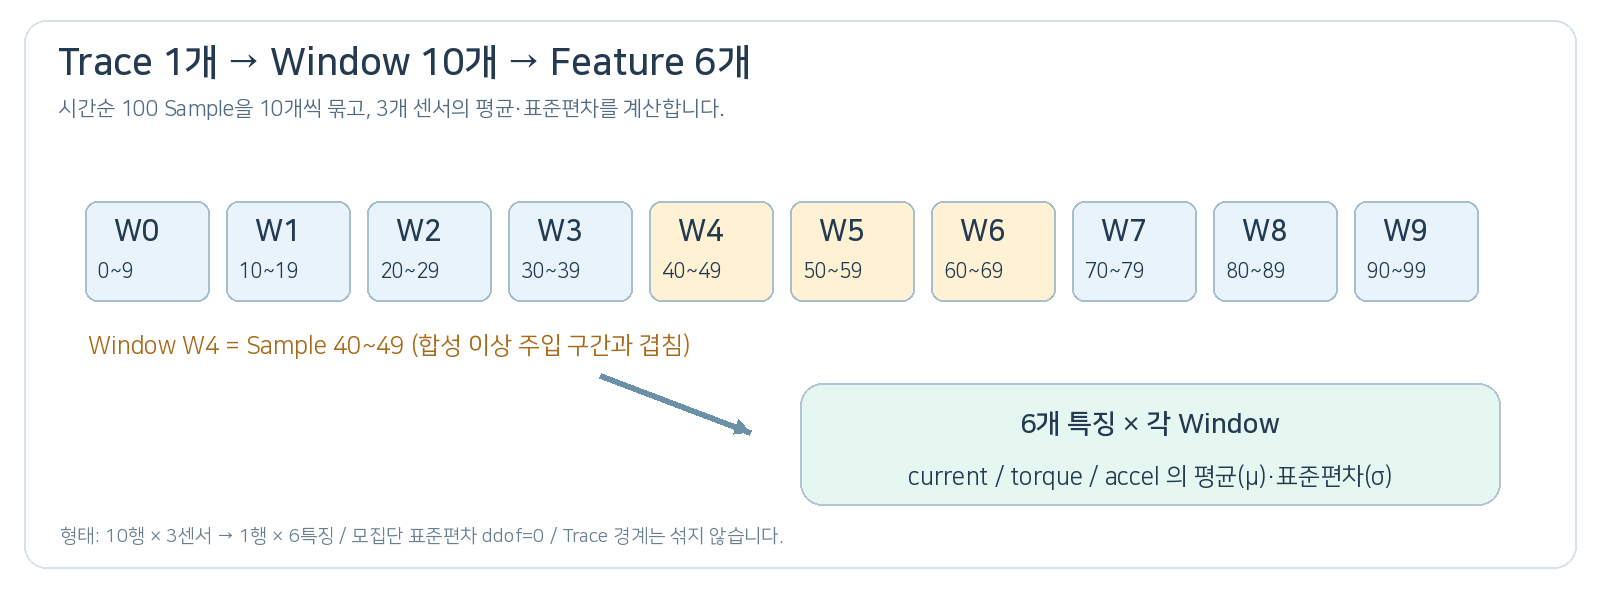

**그림 읽기:** Sample 40~49는 W4이고, 실제 코드에서 3개 센서 각각 mean/std를 계산하여 `(10,3) → (6,)` 변환을 수행합니다.


### 코드 설명 · STEP 2 — “계산 가능한 Window만 특징을 만든다”

1. `quality_check(group)`는 동일 Trace의 **Sample 번호 0~99, 결측, 시각 역행, 0.1초 간격**을 차례로 검사합니다. `truth_label`을 품질 판정에 사용하지 않습니다.
2. 품질이 `VALID`이면 Window 0~9 각각에서 세 신호의 `np.mean`과 `np.std(ddof=0)`을 계산합니다. `ddof=0`은 **모집단 표준편차**입니다.
3. 품질이 불량한 Trace는 **임의 0 대체 없이**, `INSUFFICIENT_DATA` 상태행 하나를 남깁니다.
4. **출력 Tensor 준비:** `X_train.shape=(240,6)`, `X_valid.shape=(80,6)`, `X_test.shape=(100,6)`입니다. `truth_label`은 모델의 6개 입력 특징에 포함되지 않고 **시험 평가**에만 사용됩니다.

**예상 출력:** 전체 `windows_df` 424행 = 정상 Train 240 + 정상 Valid 80 + 유효 Test 100 + 품질 상태 4. `assert`는 분할 간 Trace 겹침과 특징 유한성도 확인합니다.


In [ ]:
FEATURES = ["current_a_mean","current_a_std","torque_nm_mean","torque_nm_std",
            "accel_mps2_mean","accel_mps2_std"]
SENSORS = ["current_a","torque_nm","accel_mps2"]

def quality_check(group):
    idx=group.sample_idx.to_numpy(dtype=int)
    if not np.array_equal(idx,np.arange(100)):
        return "SAMPLE_GAP"
    if group[SENSORS].isna().to_numpy().any():
        return "MISSING_VALUE"
    stamps=group.timestamp_ns.to_numpy(dtype=np.int64)
    diffs=np.diff(stamps)
    if np.any(diffs <= 0):
        return "STAMP_REGRESSION"
    if np.any(diffs != DT_NS):
        return "TIMESTAMP_DRIFT"
    return "VALID"

def summarize_windows(frame):
    records=[]
    for tid,group in frame.groupby('trace_id',sort=True):
        group=group.sort_values('sample_idx')
        status=quality_check(group)
        split=str(group.iloc[0]['split'])
        if status != "VALID":
            records.append(dict(split=split,trace_id=tid,window_id=0,status="INSUFFICIENT_DATA",
                                quality_reason=status,truth_label=-1,
                                **{f:np.nan for f in FEATURES}))
            continue
        for w in range(10):
            block=group.iloc[w*10:(w+1)*10]
            assert len(block)==10 and block.sample_idx.to_list()==list(range(w*10,(w+1)*10))
            truths=block.truth_label.unique()
            assert len(truths)==1
            feature={}
            for sensor in SENSORS:
                values=block[sensor].to_numpy(dtype=np.float64)
                feature[sensor+"_mean"]=float(np.mean(values))
                feature[sensor+"_std"]=float(np.std(values,ddof=0))
            records.append(dict(split=split,trace_id=tid,window_id=w,status="VALID",
                                quality_reason="",truth_label=int(truths[0]),**feature))
    return pd.DataFrame(records)

windows_df=summarize_windows(raw_df)
tr=windows_df[(windows_df.split=='train')&(windows_df.status=='VALID')].copy()
va=windows_df[(windows_df.split=='valid')&(windows_df.status=='VALID')].copy()
te=windows_df[(windows_df.split=='test')&(windows_df.status=='VALID')].copy()
quality=windows_df[(windows_df.split=='test')&(windows_df.status=='INSUFFICIENT_DATA')].copy()
X_train=tr[FEATURES].to_numpy(dtype=np.float32)
X_valid=va[FEATURES].to_numpy(dtype=np.float32)
X_test=te[FEATURES].to_numpy(dtype=np.float32)
y_test=te.truth_label.to_numpy(dtype=int)
assert (X_train.shape,X_valid.shape,X_test.shape)==((240,6),(80,6),(100,6))
assert np.bincount(y_test,minlength=2).tolist()==[82,18]
assert quality.shape[0]==4 and quality.quality_reason.nunique()==4
assert len(windows_df)==424 and len(te)+len(quality)==104
assert not (set(tr.trace_id)&set(va.trace_id) or set(tr.trace_id)&set(te.trace_id))
assert np.isfinite(X_train).all() and np.isfinite(X_valid).all() and np.isfinite(X_test).all()
print("raw → windows",len(raw_df),"→",len(windows_df),"(train",len(tr),"valid",len(va),"test_valid",len(te),"quality",len(quality),")")
print("X_train",X_train.shape,"X_valid",X_valid.shape,"X_test",X_test.shape)
print("Test 유효 정답 [NORMAL, ANOMALY]",np.bincount(y_test,minlength=2).tolist())
print("품질 부족 분류",quality[['trace_id','quality_reason']].to_dict('records'))
print("TRN_00 W0 특징:",tr[(tr.trace_id=='TRN_00')&(tr.window_id==0)][FEATURES].round(4).to_dict('records')[0])
print("[PASS S2] Trace 경계/품질 검사 후 10샘플→6특징, shape (240,6)/(80,6)/(100,6), 품질4건 별도")


### 출력 해설 · STEP 2

- **6특징 명명:** `current_a_mean/std`, `torque_nm_mean/std`, `accel_mps2_mean/std`가 그림과 코드에서 같은 순서입니다.
- **품질 오류 4종:** `MISSING_VALUE`(값 없음), `SAMPLE_GAP`(샘플 번호 누락), `STAMP_REGRESSION`(시간 역행), `TIMESTAMP_DRIFT`(예상과 다른 시간 간격)입니다.
- **핵심 판단:** `VALID 100개 + INSUFFICIENT_DATA 4개 = 104행`이지만 **혼동행렬 분모는 VALID 100개**입니다.

**학생 질문:** 품질 불량 Trace에도 10개 Window를 억지로 만들면 왜 안 될까요? 답: 누락/역행 때문에 원래 시간 관계가 깨진 입력에 그럴듯한 점수를 붙이게 됩니다.


## 3단계 (20분) · 정상 Train 기준 정규화와 MSE 손계산

**왜 필요한가?** 전류(A)·토크(N·m)·가속도(m/s²)는 수치 규모가 달라 어떤 특징이 큰지만으로 MSE를 지배하면 안 됩니다. 그래서 정상 Train에서 배운 평균·표준편차로 여섯 특징을 정규화합니다.

**데이터 누수(Data leakage):** `scaler.fit`도 기준을 배우는 과정입니다. **Train에서만 fit**하고, 정상 Valid에는 `transform`만 적용합니다. Test는 경고선을 고른 **다음** 단계에서 사용합니다.

**비유:** 시험에 앞서 채점 기준을 정하는 것이지, 시험 답안을 읽고 기준을 정하는 것이 아닙니다. 비유의 한계: 분포가 심하게 달라질 때는 새로운 학습·평가 절차가 따로 필요합니다.


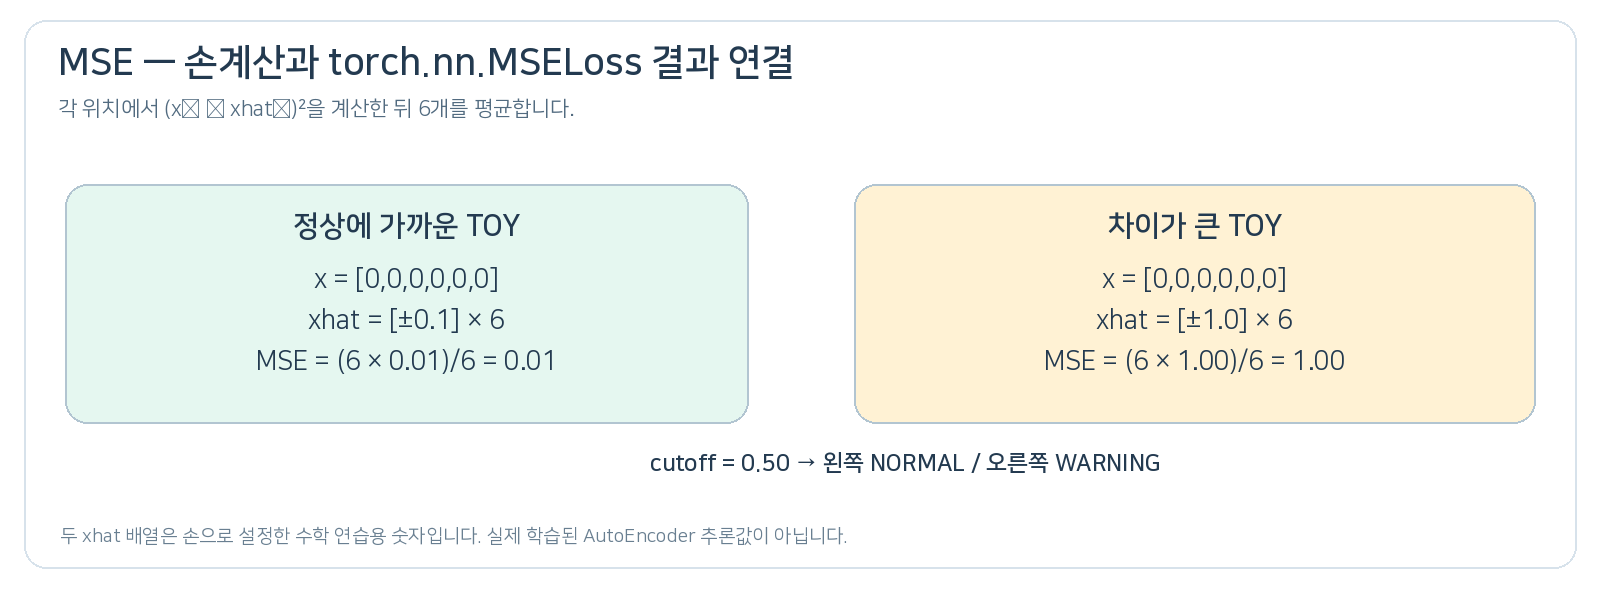

**그림 읽기:** 모델 학습 결과가 아닌 고정된 6차원 입력/복원 TOY를 사용하여 수식과 코드를 일치시킵니다.


### 수식 → 숫자 → 코드 연결

정규화 입력 **xᵢ**와 복원값 **x̂ᵢ**의 같은 위치를 비교합니다. 아래 수식은 **인터넷 없이도 표시되는 Unicode 표기**이며 실제 코드 `np.mean((x-xhat)**2, axis=1)`과 같습니다.

<div style="background:#e8f3fc;border-left:4px solid #237f9a;padding:12px 16px;font-size:20px;border-radius:7px"><b>MSE(x, x̂) = (1 / 6) Σᵢ₌₁⁶ (xᵢ − x̂ᵢ)²</b></div>

- **xᵢ:** 정규화된 6개 특징 중 i번째 값.
- **x̂ᵢ:** AutoEncoder가 같은 위치에 복원한 값. **이 손계산에서만 미리 만든 값**입니다.
- **분모 6:** 차이를 비교하는 **특징 개수**이며 Batch 크기가 아닙니다.
- **x=[0,0,0,0,0,0]**, **x̂=[0.1,−0.1,0.1,−0.1,0.1,−0.1]**이면 `6 × 0.1² / 6 = 0.01`입니다.
- **x̂=[1,−1,1,−1,1,−1]**이면 `6 × 1² / 6 = 1.00`입니다.
- 아래 `nn.MSELoss(reduction='none').mean(dim=1)`이 이 수식과 일치하는지 `np.allclose`로 검증합니다. float32 계산 오차를 고려해 `atol=1e-7`, `rtol=1e-6`을 사용합니다.

### 코드 설명 · STEP 3 — “Train-only scaler와 수학 계산을 대조한다”

`StandardScaler.fit_transform(X_train)`은 Train의 평균 `mean_`·표준편차 `scale_`을 기억합니다. `transform(X_valid)`은 **그 저장된 기준을 사용**합니다. 실제 수식 `(X_valid − mean_)/scale_`과 결과가 같은지 검사합니다. **아직 AE 모델을 학습하거나 Test를 사용하지 않습니다.**


In [ ]:
# Scaler의 fit은 Train만 사용합니다. Valid와 Test의 정답으로 기준을 바꾸지 않습니다.
scaler=StandardScaler()
Z_train=scaler.fit_transform(X_train).astype(np.float32)
Z_valid=scaler.transform(X_valid).astype(np.float32)
assert Z_train.shape==(240,6) and Z_valid.shape==(80,6)
assert np.allclose(Z_train.mean(axis=0),0,atol=5e-6)  # float32 rounding
assert np.allclose(Z_train.std(axis=0,ddof=0),1,atol=1e-5)
assert np.isfinite(Z_train).all() and np.isfinite(Z_valid).all()
# 분자·분모를 직접 계산해 sklearn transform의 결과와 확인합니다.
manual_z=(X_valid.astype(np.float64)-scaler.mean_)/scaler.scale_
assert np.allclose(manual_z,Z_valid,atol=1e-5,rtol=1e-5)
# 6차원 작은 수학 TOY: 학습된 AE의 출력이 아니라 미리 지정한 xhat입니다.
toy_x=np.zeros((2,6),dtype=np.float32)
toy_xhat=np.array([[.1,-.1,.1,-.1,.1,-.1],[1,-1,1,-1,1,-1]],dtype=np.float32)
toy_manual=np.mean((toy_x-toy_xhat)**2,axis=1)
toy_torch=nn.MSELoss(reduction='none')(torch.tensor(toy_x, device=DEVICE),torch.tensor(toy_xhat, device=DEVICE)).mean(dim=1)
toy_torch_np=toy_torch.detach().cpu().numpy()  # NumPy/Matplotlib 연계는 CPU로 복사
assert toy_x.shape==toy_xhat.shape==(2,6)
assert np.allclose(toy_manual,toy_torch_np,rtol=1e-6,atol=1e-7)
assert np.allclose(toy_manual,[0.01,1.0],atol=1e-7)
print("Train scaler mean",np.round(scaler.mean_,4))
print("Train scaler scale",np.round(scaler.scale_,4))
print("Z_train / Z_valid",Z_train.shape,Z_valid.shape)
print("TOY MSE manual",np.round(toy_manual,6),"PyTorch",np.round(toy_torch_np,6))
print("TOY cutoff 0.5 =>",["WARNING" if s>0.5 else "NORMAL" for s in toy_manual])
print("[PASS S3] Train-only StandardScaler·수식 일치·6D TOY MSE 0.01 / 1.0 확인")


### 출력 해설 · STEP 3

- `Z_train`, `Z_valid`의 두 번째 축 6은 특징 수이고, 첫 번째 축 240/80은 Window 수입니다. 이 두 배열은 스케일러를 거친 실제 계산 결과입니다.
- `TOY MSE manual [0.01, 1.0] / PyTorch [0.01, 1.0]`는 **손제작 예제와 라이브러리 수식이 같음**을 보여줍니다.
- TOY cutoff 0.5는 **설명용으로 임의 선정**한 값입니다. 뒤의 실제 AE cutoff와 섞어 쓰지 않습니다.
- float32의 정규화 평균이 0에서 약 몇 백만분의 1 어긋날 수 있어 `atol=5e-6`으로 비교합니다. 이는 검증 완화가 아니라 자료형의 반올림을 고려한 근거 있는 허용오차입니다.

**학생 질문:** 모든 6특징을 그대로 모델 입력에 넣는 대신 `truth_label`까지 넣으면 어떤 문제가 생길까요? 답: 시험 정답이 모델 입력에 노출되는 누수입니다.


## 4단계 (45분) · 실제 PyTorch AutoEncoder 학습하기

**상황:** 이제 손으로 지정한 `xhat`이 아니라 **모델의 학습된 가중치가 직접 만든 복원값**을 확인합니다. 정상 Train 240 Window로 가중치를 학습하고, 나중에 다른 데이터의 재구성 오차를 계산합니다.

**Encoder(인코더):** 여섯 특징을 8차원으로 확장했다가 **3차원 잠재 표현**으로 압축합니다. **Decoder(디코더):** 3차원을 8차원으로 확장했다가 다시 여섯 특징으로 복원합니다. 가운데 3개는 전류·토크·가속도 고장 클래스 세 가지가 아닙니다.


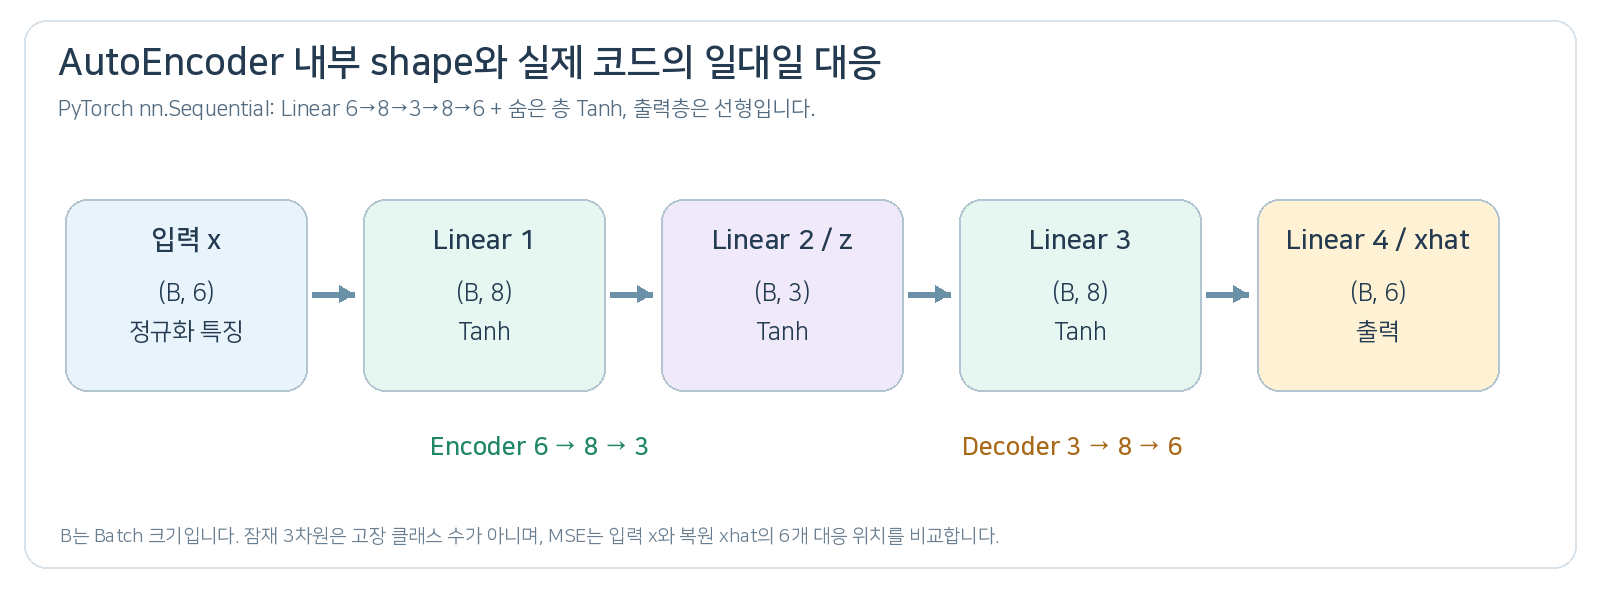

**그림 읽기:** 실제 코드 `nn.Linear(6,8), nn.Linear(8,3), nn.Linear(3,8), nn.Linear(8,6)`와 `(B,6)→(B,8)→(B,3)→(B,8)→(B,6)`를 매칭합니다.


### STEP 4 — 직접 AutoEncoder 구조와 학습 과정을 채워 보세요

**왜 필요한가요?** 정상 Train의 6개 특징을 6→8→3→8→6 구조로 복원하면 입력과 복원값의 MSE를 계산할 수 있습니다. 아래 셀은 강사 정답이 아닌 **TODO 골격**입니다. `torch.nn.Sequential`, 손실 함수, `zero_grad/backward/step`을 스스로 구현합니다. 아직은 `[EXPECTED_RED S4]`만 출력하며 모델 학습 PASS가 아닙니다.

**입출력 목표:** Z_train: (240,6) → 신경망 출력: (240,6). 중간 shape (240,8) → (240,3) → (240,8)입니다.


In [ ]:
# D11 학생용 TODO S4 — 정상 Train만 사용해 AE 구조·학습 구현
# 입력 Z_train shape=(240,6); 원하는 모델 출력 shape=(240,6)
# Encoder 6→8→3, Decoder 3→8→6; latent 3은 고장 클래스 수가 아닙니다.
def train_autoencoder_todo(Z_train, device):
    raise NotImplementedError("D11 TODO S4: build/train/verify AutoEncoder")
print("[EXPECTED_RED S4] AE 학습 함수는 학생 구현 전입니다. 모델 PASS가 아닙니다.")


### STEP 4 예상 출력 및 검증

원본 TODO 상태에서는 **`[EXPECTED_RED S4]`**만 출력합니다. 실행 오류 없이 셀이 끝났다는 사실은 모델 학습이 성공했다는 뜻이 아닙니다. 직접 완성했다면 실제 학습 손실 감소·입출력 shape·장치 일치를 검증한 뒤에만 `[PASS S4]`라고 보고하십시오.


## 5단계 (45분) · 정상 Valid로 경계선을 고정하고 Test에서 판정하기

**현장 문제:** 모델이 MSE를 낼 수 있어도 **얼마 이상이면 WARNING**인지 정해야 합니다. 그리고 샘플 자체가 누락된 경우에는 MSE를 0으로 만들어 정상이라고 말해서는 안 됩니다.

**95% 분위수(95th percentile):** 정상 Valid 80개의 MSE를 정렬했을 때 약 95%가 그 이하에 해당하는 수준입니다. 정상 Valid에서도 약 5%는 경고선을 넘을 수 있습니다. 이 수업의 cutoff는 **정상 Valid를 이용한 경험적 기준**이며 실제 안전 인증 기준이 아닙니다.


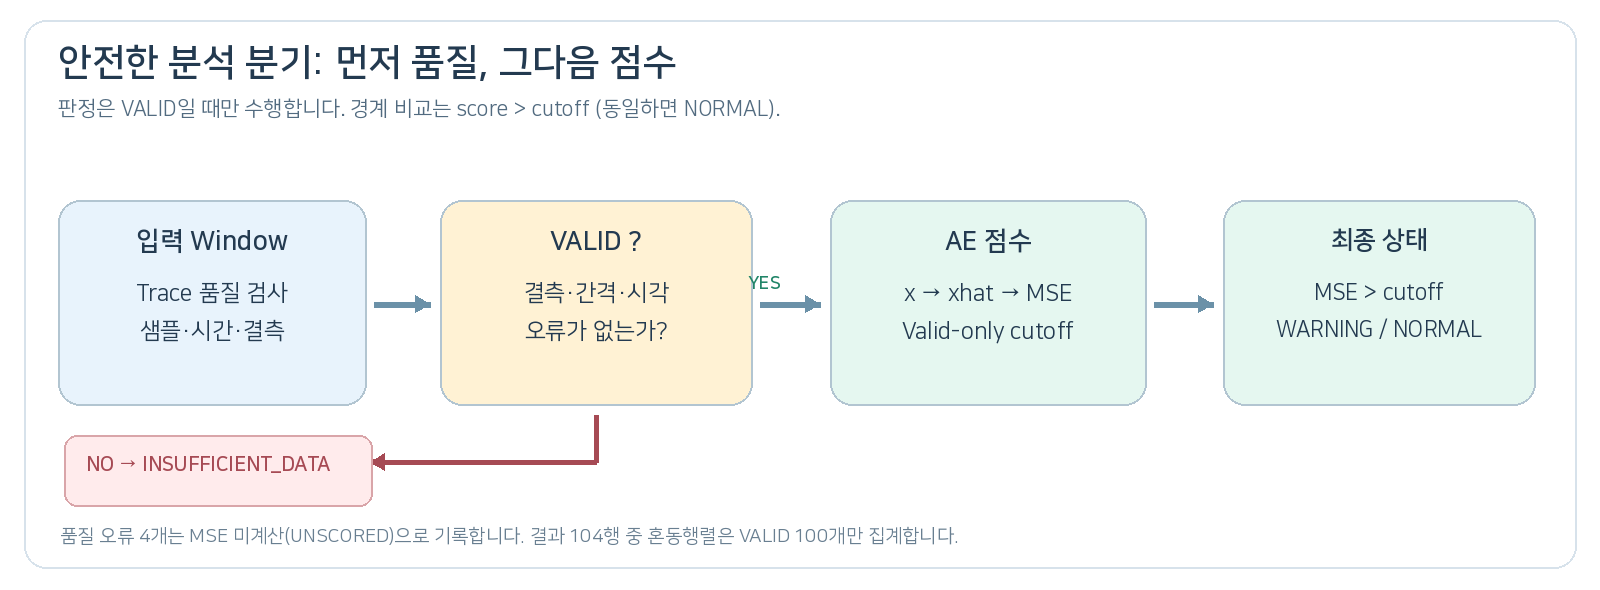

**그림 읽기:** 품질 오류 네 Trace는 점수 없는 INSUFFICIENT_DATA이며, VALID일 때만 MSE가 threshold보다 크면 WARNING입니다.


### STEP 5 — Valid-only cutoff를 직접 구현하세요

**설계 이유:** Test 정답을 보고 cutoff를 조절하면 데이터 누수가 생깁니다. 정상 Valid 80개에 대한 재구성 MSE의 95% 분위수로 기준을 고정한 다음 Test를 평가하세요. 품질이 VALID가 아닌 4개 상태행은 **UNSCORED / INSUFFICIENT_DATA**로 남겨야 합니다.

**TODO 구현 목표:** 복원 점수 → Valid-only cutoff → Test100 유효 / 품질4 분리 → NORMAL/WARNING/INSUFFICIENT_DATA. 원본 셀은 실제 AE 모델을 실행하지 않습니다.


In [ ]:
# D11 학생용 TODO S5 — Train-only scaler / Valid-only cutoff / Test holdout
# Test 100 VALID + 품질 상태 4개를 구분하세요.
def valid_cutoff_and_test_todo(model, Z_valid, test_features):
    raise NotImplementedError("D11 TODO S5: valid-only threshold and quality gate")
print("[EXPECTED_RED S5] Valid cutoff와 Test 판정 미구현; 실제 추론 PASS 아님.")


### STEP 5 예상 출력 및 검증

원본에서는 `[EXPECTED_RED S5]`만 출력합니다. 직접 완성한 경우 cutoff 출처가 정상 Valid인지, Test를 학습/기준 조정에 사용하지 않았는지, 품질 4개에 점수를 붙이지 않았는지 독립적으로 검증하십시오. 과거 강사 참조 수치를 실제 내 실행으로 보고하지 않습니다.


## 6단계 (30분) · D10 Isolation Forest와 같은 Test로 비교하기

**왜 필요한가?** 지난 D10 모델은 얼마나 고립되기 쉬운지를 살폈고, 이번 D11 AE는 정상 패턴을 얼마나 복원하기 어려운지를 계산합니다. 두 점수의 정의가 다르므로 **cutoff 원점수 숫자만 비교해 우열을 정하면 안 됩니다**.

**비교의 공정성:** 두 모델 모두 정상 Train 240으로 학습하고 정상 Valid 80에서 각자 cutoff를 선택합니다. **같은 Test 유효 100개**로 TP/FP/FN/TN을 계산하며, 품질4개는 두 모델 모두 평가에서 제외합니다.


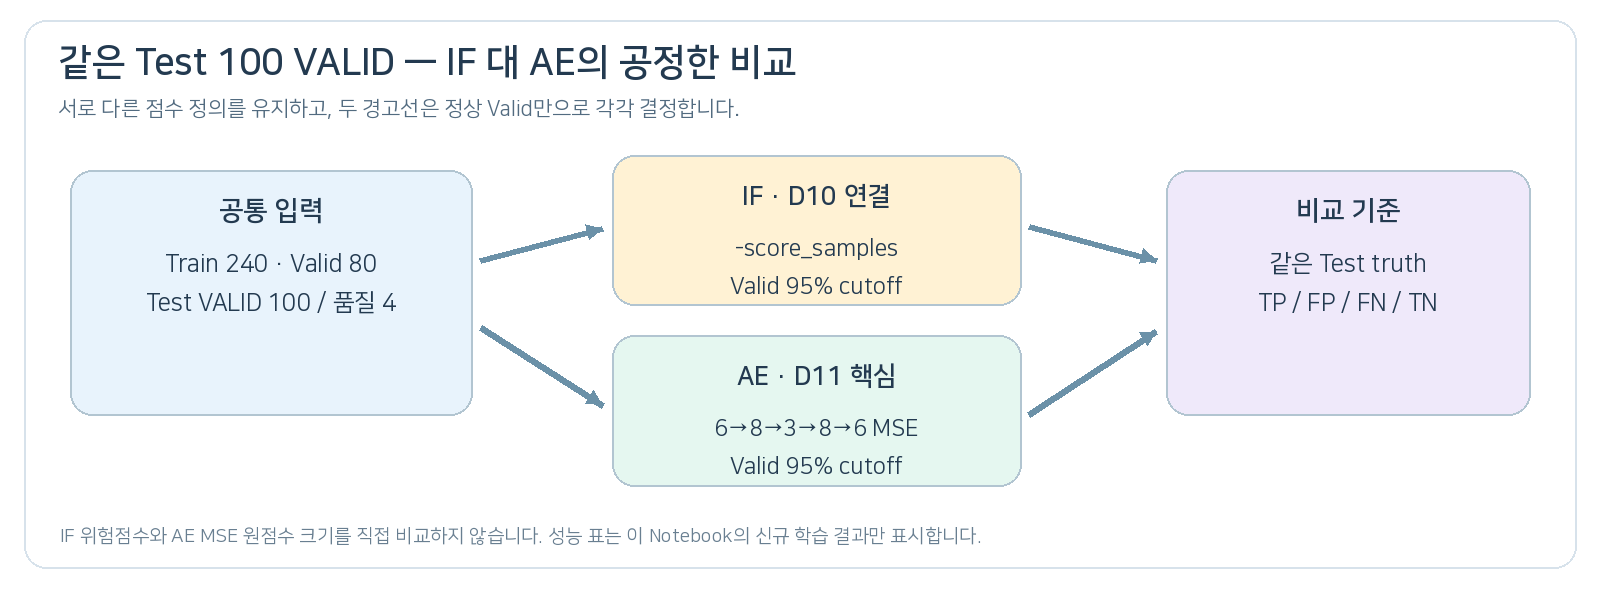

**그림 읽기:** 같은 합성 데이터·같은 Test를 공유하되 모델별 점수·임계값은 서로 섞지 않습니다. 결론은 실제 출력된 평가표로 내립니다.


### STEP 6 — D10 Isolation Forest와 D11 AE를 같은 Test로 비교하세요

**왜 같은 Test를 쓰나요?** 서로 다른 시험지를 사용하면 모델 성능을 공정하게 비교할 수 없습니다. 두 모델은 점수 척도가 다르므로 IF 점수와 AE MSE의 크기를 직접 비교하지 않습니다.

**TODO 구현 목표:** 같은 Test VALID100에 대해 두 모델의 TP/FP/FN/TN과 Precision/Recall을 계산하고 정상 오탐(FP)과 이상 미탐(FN)을 설명합니다. 공개 학생 Notebook에는 정답 모델 코드가 포함되지 않습니다.


In [ ]:
# D11 학생용 TODO S6 — 동일 Test 100 VALID의 IF/AE 결과 비교
# TP+FP+FN+TN=100 / 품질 실패 4개는 혼동행렬에서 제외.
def compare_if_ae_todo(X_train, X_test_valid, truth_valid):
    raise NotImplementedError("D11 TODO S6: IF-vs-AE confusion and analysis")
print("[EXPECTED_RED S6] IF/AE 비교는 학생이 직접 완성해야 합니다.")


### STEP 6 예상 출력 및 검증

원본에서는 `[EXPECTED_RED S6]`만 출력합니다. 과제 완료 후에는 `TP+FP+FN+TN=100`인지 확인하고, 품질 불량 4건은 분모에서 제외하세요. 실제 학습 전에는 성능 수치를 임의로 적지 않습니다.


## 최종 정리 — 어떤 부분을 직접 실행했나요?

- S1 합성 원본 생성, S2 Trace→Window 6특징 추출, S3 정상 Train scaler 및 MSE TOY는 실행 가능한 **학습 공통 단계**입니다.
- S4 실제 AE 학습, S5 Valid-only 임계값 및 Test 추론, S6 IF/AE 비교는 학생이 완성할 **TODO**입니다. 미완성 시 `EXPECTED_RED`로 보고합니다.
- 완성된 강사 AE 정답·checkpoint는 비공개 저장소에 있습니다. 강사에게 시연을 요청하고 자신의 결과와 혼동하지 마세요.
- 합성 데이터의 WARNING은 로봇의 SW Stop이나 인증된 E-Stop으로 연결되지 않습니다.


## 스스로 점검 — 정답은 자신의 실행 증거로 설명합니다

1. **왜 Trace 단위로 Train/Valid/Test를 먼저 나누나요?** 같은 사건의 Window가 학습과 평가 양쪽에 들어가는 누수를 막기 위해서입니다.
2. **6개 특징은 무엇인가요?** 세 신호(current/torque/accel)의 평균과 표준편차입니다.
3. **왜 Encoder 6→8→3 / Decoder 3→8→6이 필요한가요?** 입력을 잠재 표현으로 압축하고 원래 6차원으로 복원해 MSE를 계산합니다.
4. **어디에 scaler.fit을 수행해야 하나요?** 정상 Train에서만입니다.
5. **cutoff는 어디서 정하나요?** 정상 Valid MSE의 95% 분위수입니다.
6. **품질 4개를 NORMAL=0으로 바꿔도 되나요?** 아니요. INSUFFICIENT_DATA로 미점수 상태를 보존합니다.
7. **이 Notebook에서 코드 7개가 오류 없이 끝나면 AE도 PASS인가요?** 아닙니다. S4~S6은 원래 TODO이며 별도 검증이 필요합니다.
8. **교육 WARNING이 실제 인증된 E-Stop인가요?** 아닙니다. 실제 로봇 제어 기능은 없습니다.
